In [1]:
# Setup dataset
import numpy as np
from dynamics_testing import sim, attractor_dist, make_train

SEG, SETTLE, REENTRAIN, N_AUTO, DISCARD, WARM_TRAIN = 2000, 1000, 50, 1200, 200, 200
STATES = ["chaotic", "periodic_A", "periodic_B"]
RS_ROT = 700
N_STEPS = SETTLE + RS_ROT + N_AUTO

def rhs(_, y, b):
    x, yy, z = y
    return [np.sin(yy) - b * x, np.sin(z) - b * yy, np.sin(x) - b * z]

TRAIN = multi_t[:, :4 * SEG] if "multi_t" in globals() else make_train(rhs, SEG)

def make_ref(n_ics, n_steps, seed):
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(rhs, 0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)], "periodic_A": [], "periodic_B": []}
    ex = None
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        tr = sim(rhs, 0.29, n_steps, rng.uniform(-4, 4, 3)); ex = tr if ex is None else ex
        k = "periodic_A" if attractor_dist(tr, ex) < 0.1 else "periodic_B"
        if len(out[k]) < n_ics: out[k].append(tr)
    return {k: np.concatenate(v, axis=1) for k, v in out.items()}

REF = make_ref(2, 5000, seed=300)
ref_label = lambda tr: min(("periodic_A", "periodic_B"), key=lambda k: attractor_dist(tr, REF[k]))

def make_states(n_ics, n_steps, seed):
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(rhs, 0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)], "periodic_A": [], "periodic_B": []}
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        tr = sim(rhs, 0.29, n_steps, rng.uniform(-4, 4, 3)); k = ref_label(tr)
        if len(out[k]) < n_ics: out[k].append(tr)
    return out

VAL, TEST = make_states(4, N_STEPS, seed=100), make_states(4, N_STEPS, seed=200)

In [2]:
# Setup model testing harnesses and train model
import testing_harness

RS_OMEGA0 = 0.01
RN_BASE = dict(input_dims=3, spectral_radius=0.6, input_weight=1.2, average_degree_nodes=10, num_nodes=100,
               leakage=0, omega0=RS_OMEGA0, epsilon1=-0.2, epsilon2=0.6,
               mean_phase_tolerance=RS_OMEGA0,          # >= one rotation step, so the pi-crossing can't be skipped
               error_tolerance=np.inf)                  # freeze on phase alone

train_fn, settle_fn = testing_harness.get_harness()["spk"]
net_1, W_1 = train_fn(RN_BASE, 4, 1, TRAIN, WARM_TRAIN, save_hist=True)
net_0, W_0 = train_fn(RN_BASE, 4, 0, TRAIN, WARM_TRAIN, save_hist=True)

In [46]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

SMALL_SIZE = 10
MEDIUM_SIZE = 13
BIGGER_SIZE = 20

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=MEDIUM_SIZE, labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

colors = mpl.colormaps['Dark2'].colors
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=colors)
cmap = LinearSegmentedColormap.from_list(name="cmap", colors=[colors[3], "#FFFFFF", colors[4]])

In [47]:
import copy

fig, axes = plt.subplots(1, 2)
for ax, x in zip(axes, (TEST["chaotic"][0], TEST["periodic_A"][0])):
    net = copy.deepcopy(net_1)
    net.reset_initial_states(1); net.reset_history()
    for t in range(SETTLE):
        net.advance(x[:, t], save_history=False)
    order = np.argsort(np.angle(net.rel_lp))               # links sorted by settled offset
    rank = np.empty_like(order); rank[order] = np.arange(len(order))
    t_start, prev, spikes = net.link_time, net.last_spike.copy(), []
    for t in range(SETTLE, SETTLE + 50):
        net.advance(x[:, t], save_history=False)
        new = np.flatnonzero(net.last_spike != prev)
        spikes += [((net.last_spike[i] - t_start) / net.dt_link, rank[i]) for i in new]   # reservoir steps
        prev = net.last_spike.copy()
    s = np.asarray(spikes)
    ax.scatter(s[:, 0], s[:, 1], s=1)
plt.show()

KeyboardInterrupt: 

Error in callback <function flush_figures at 0x000001BF15E9DE40> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

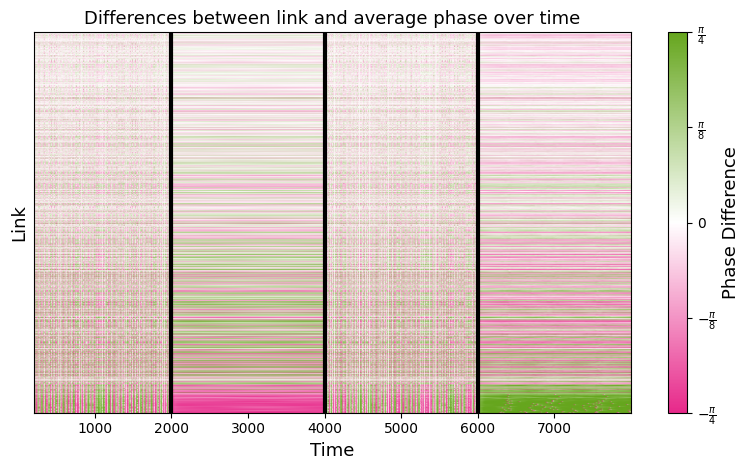

In [48]:
_, _, P, _ = net_1.get_history()                                   # link phases: links x T
psi = np.angle(np.nanmean(np.exp(1j * P), axis=0))                 # global mean phase per step
rel = np.angle(np.exp(1j * (P - psi)))                             # instantaneous offset, wrapped to (-pi, pi]
rel_lp = np.angle(np.asarray(net_1.rel_lp_history)).T              # smoothed offset (what the model uses)

steps = WARM_TRAIN + np.arange(P.shape[1])
per = ((steps // SEG) % 2 == 1) & ((steps % SEG) >= 500)
order = np.argsort(rel_lp[:, per & (steps < 4 * SEG)].mean(axis=1))                    # sort links by settled periodic offset

lim = np.pi/4 # = np.percentile(np.abs(rel_lp), 99)                            # or np.pi for the literal scale
for M in (rel,):#, rel_lp):
    plt.figure(figsize=(6.4*1.25, 4.8))
    
    plt.imshow(M[order], aspect="auto", cmap=cmap, vmin=-lim, vmax=lim, extent=[steps[0], steps[-1], 0, M.shape[0]])
    
    cbar = plt.colorbar(label="Phase Difference", ticks=[-np.pi/4, -np.pi/8, 0, np.pi/8, np.pi/4])
    cbar.ax.set_yticklabels([r'$-\frac{\pi}{4}$', r'$-\frac{\pi}{8}$', r'$0$', r'$\frac{\pi}{8}$', r'$\frac{\pi}{4}$'])

    plt.axvline(2000, linewidth=3, color="black")
    plt.axvline(4000, linewidth=3, color="black")
    plt.axvline(6000, linewidth=3, color="black")
    
    plt.ylabel("Link")
    plt.yticks([])
    
    plt.xlabel("Time")

    plt.title("Differences between link and average phase over time")
    plt.tight_layout()

    plt.savefig("phase_diff.pdf")
    plt.show()

regime 0: K_eff = 0.1169 rad/step
regime 1: K_eff = 0.1651 rad/step


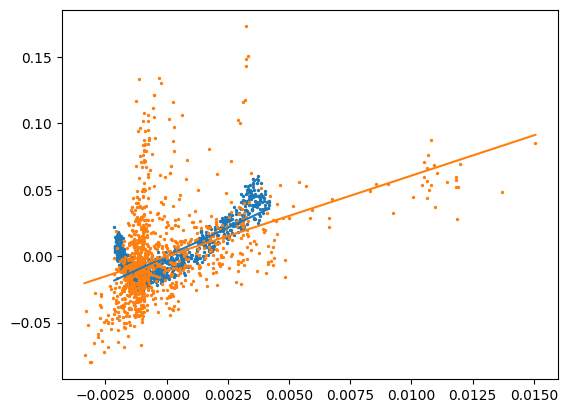

In [23]:
H, _, _, _ = net_1.get_history()                                       # nodes x T
Z = np.asarray(net_1.rel_lp_history)                                   # T x links
drive = (net_1.incidence_T @ ((H + 1) / 2)) / net_1.incidence_norm[:, None]   # links x T
I_ext = np.maximum(net_1.I_ref + net_1.g_freq * (drive - 0.5), net_1.I_ref - 14)  # I_FLOOR = I_c + 1 = I_ref - 14

# natural frequency per link from the measured f-I curve (rad per reservoir step), interpolated
ref = copy.deepcopy(net_1)
I_grid = np.linspace(I_ext.min(), I_ext.max(), 15)
w_grid = np.array([2 * np.pi * ref.dt_link / ref.reference_period(I) for I in I_grid])

steps = WARM_TRAIN + np.arange(Z.shape[0])
regime = (steps // SEG) % 2                                            # 0 chaotic, 1 periodic
steady = (steps % SEG) >= 500                                          # skip context settling after each switch

for r in (0, 1):
    m = (regime == r) & steady
    w = np.interp(I_ext[:, m].mean(axis=1), I_grid, w_grid)
    dw = w - w.mean()                                                  # detuning from the population frequency
    phi = np.angle(Z[m].mean(axis=0))                                  # locked offset from the global mean phase
    K_eff = np.sum(dw ** 2) / np.sum(dw * np.sin(phi))                 # one fitted parameter: sin(phi) = dw / K_eff
    plt.scatter(dw, phi, s=2)
    xs = np.linspace(dw.min(), dw.max(), 200)
    plt.plot(xs, np.arcsin(np.clip(xs / K_eff, -1, 1)))
    print(f"regime {r}: K_eff = {K_eff:.4f} rad/step")
plt.show()

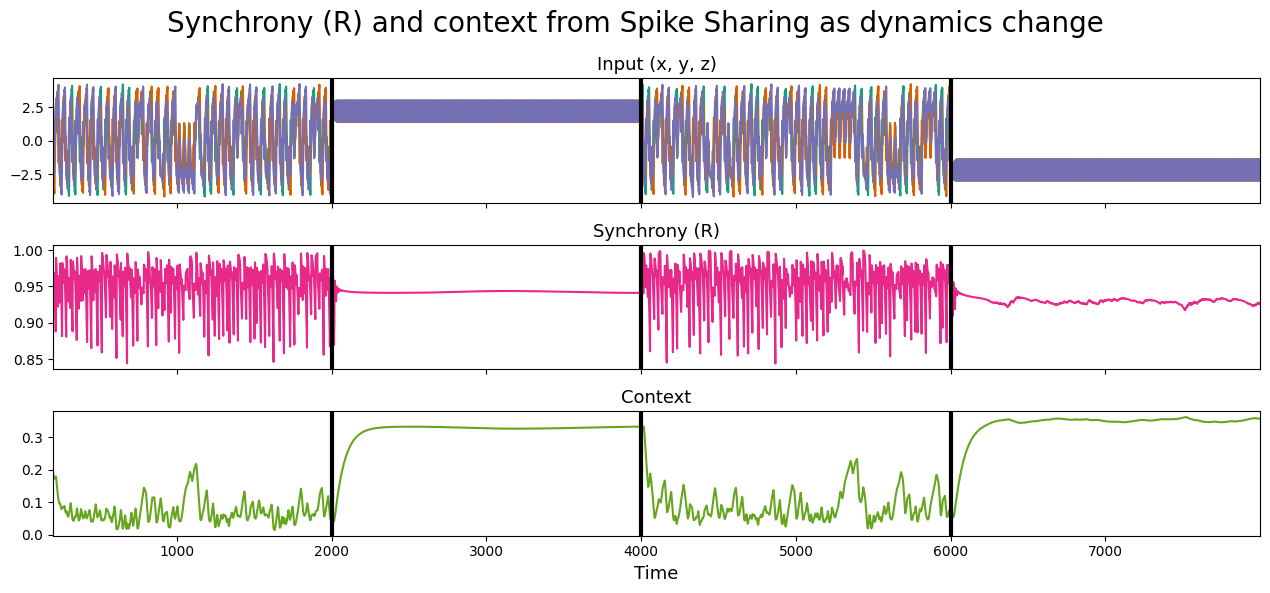

In [50]:
_, _, _, U = net_1.get_history()                                       # 3 x T training input
R, _ = net_1.get_global_parameters()                                   # read-only
Z = np.asarray(net_1.rel_lp_history)                                   # T x links

steps = WARM_TRAIN + np.arange(Z.shape[0])
ref_mask = ((steps // SEG) % 2 == 0) & ((steps % SEG) >= 500)          # steady part of the chaotic segments
ref_mask &= steps < 2 * SEG                                            # first chaotic segment only
ctx = np.sqrt(np.mean(np.abs(Z - Z[ref_mask].mean(axis=0)) ** 2, axis=1))

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(6.4 * 2, 4.8*1.25))

axes[0].plot(steps, U.T)
axes[0].set_xlim(min(steps), max(steps))
axes[0].set_title("Input (x, y, z)")

axes[1].plot(steps, R, color=colors[3])
axes[1].set_title("Synchrony (R)")

axes[2].plot(steps, ctx, color=colors[4])
axes[2].set_title("Context")
axes[2].set_xlabel("Time")

fig.suptitle("Synchrony (R) and context from Spike Sharing as dynamics change")

for ax in axes:
    for b in range(SEG, steps[-1] + 1, SEG):
        ax.axvline(b, linewidth=3, color="black")

plt.tight_layout()
plt.savefig("timeseries.pdf")
plt.show()

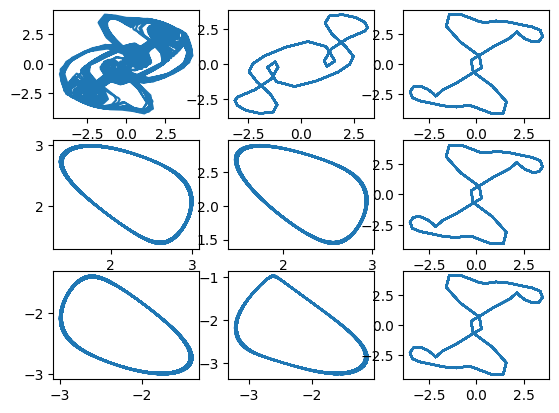

In [36]:
BEST = {'RN_c0': 0.1, 'RN_pub': 1e-08, 'spike_c0': 0.1, 'spike_c1.0': 0.01}

nets = {}
for name, net, key in (("c1", net_1, "spike_c1.0"), ("c0", net_0, "spike_c0")):
    n = copy.deepcopy(net)
    n.regularization = BEST[key]
    n.compute_weights()                                                # readout at the alpha chosen on validation
    nets[name] = n

states = ["chaotic", "periodic_A", "periodic_B"]
fig, axes = plt.subplots(len(states), 3)
for row, s in zip(axes, states):
    x = TEST[s][0]
    row[0].plot(x[0, SETTLE:], x[1, SETTLE:])
    for ax, name in zip(row[1:], ("c1", "c0")):
        p, _ = copy.deepcopy(nets[name]).predict(x, SETTLE, REENTRAIN, N_AUTO, offset=1)
        ax.plot(p[0, DISCARD:], p[1, DISCARD:])
plt.show()

In [52]:
from scipy.spatial import cKDTree
from dynamics_testing import classify
from tqdm import tqdm

# readout at the validation alpha (on a copy)
net = copy.deepcopy(net_1)
net.regularization = BEST["spike_c1.0"]
net.compute_weights()

def settle(x, offset=1):
    w = copy.deepcopy(net)
    w.reset_initial_states(offset); w.reset_history()
    for t in range(SETTLE):
        w.advance(x[:, t], save_history=False)
    return w

# frozen contexts: chaotic from IC 2 (lambda ~ true value), periodic from IC 0 of each orbit
Z = {"chaotic":    settle(TEST["chaotic"][2], offset=3).rel_lp.copy(),
     "periodic_A": settle(TEST["periodic_A"][0], offset=1).rel_lp.copy(),
     "periodic_B": settle(TEST["periodic_B"][0], offset=1).rel_lp.copy()}

# switch into a periodic context only when the output is nearer (3-D) to that orbit than to the other
TREE = {s: cKDTree(REF[s].T) for s in ("periodic_A", "periodic_B")}
def nearer(out, target):
    other = "periodic_B" if target == "periodic_A" else "periodic_A"
    return TREE[target].query(out)[0] < TREE[other].query(out)[0]

# start: settle and re-entrain on chaotic drive, then run autonomously
x = TEST["chaotic"][2]
w = settle(x, offset=3)
w.frozen = True
for t in tqdm(range(SETTLE, SETTLE + REENTRAIN)):
    w.advance_nodes(x[:, t], save_history=False)

SCHEDULE = [("chaotic", 400), ("periodic_A", 400), ("chaotic", 400), ("periodic_B", 400), ("chaotic", 400)]
HOLD, MAX_WAIT = 3, 400                       # steps the output must stay near the target orbit; cap on waiting
P, bounds = [], [0]
for k, (s, n) in enumerate(SCHEDULE):
    w.rel_lp = Z[s].copy()                    # swap the frozen context; no input from here on
    nxt = SCHEDULE[k + 1][0] if k + 1 < len(SCHEDULE) else None
    run = 0
    for step in range(n + MAX_WAIT):
        out = w.output_weights @ w.node_states
        if step >= n:                         # minimum segment length reached: decide when to switch
            if nxt not in TREE:
                break                         # next segment is chaotic (or none): switch now
            run = run + 1 if nearer(out, nxt) else 0
            if run >= HOLD:
                break                         # output is in the next orbit's region: switch now
        P.append(out)
        w.advance_nodes(out, save_history=False)
    bounds.append(len(P))
P = np.asarray(P).T

for (s, _), a, b in zip(SCHEDULE, bounds[:-1], bounds[1:]):
    print(f"steps {a}-{b}: context {s:11s} -> output {classify(P[:, b - 300:b], REF)[0]}")

100%|████████████████████████████████████████████████████████████████████████████████| 50/50 [00:00<00:00, 8991.39it/s]


steps 0-410: context chaotic     -> output none
steps 410-810: context periodic_A  -> output periodic_A
steps 810-1212: context chaotic     -> output chaotic
steps 1212-1612: context periodic_B  -> output periodic_B
steps 1612-2012: context chaotic     -> output chaotic


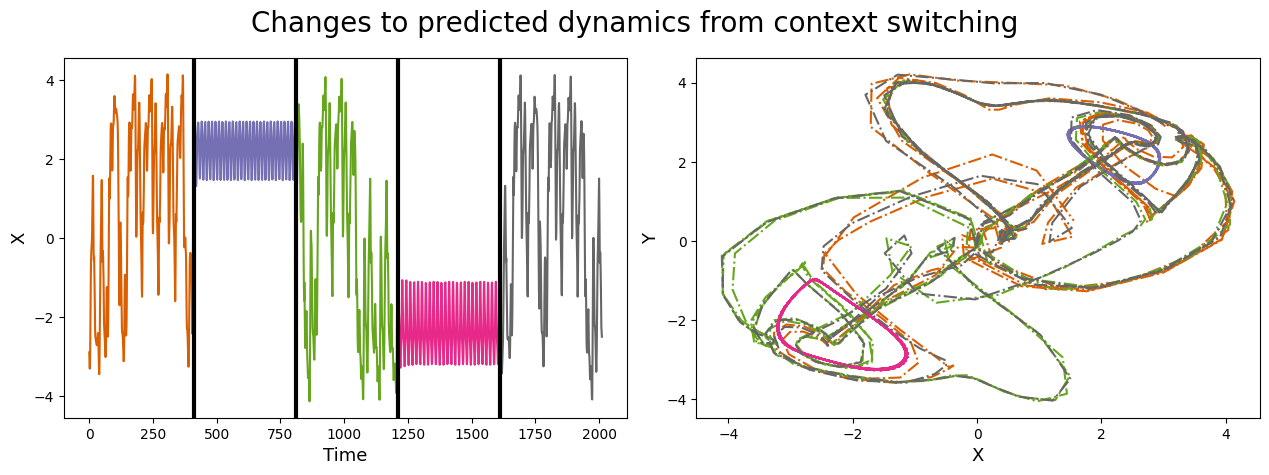

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(6.4 * 2, 4.8))

colors_temp = [colors[1], colors[2], colors[4], colors[3], colors[-1]]

for i in range(len(bounds) - 1):
    axes[0].plot(range(bounds[i], bounds[i+1]), P[0, bounds[i]:bounds[i+1]], color=colors_temp[i])

for b in bounds[1:-1]:
    axes[0].axvline(b, linewidth=3, color="black")

axes[0].set_ylabel("X")
axes[0].set_xlabel("Time")

axes[1].plot(P[0, bounds[1] - 300:bounds[1]], P[1, bounds[1] - 300:bounds[1]], linestyle="-.", color=colors_temp[0])   # segment 1: chaotic context
axes[1].plot(P[0, bounds[2] - 300:bounds[2]], P[1, bounds[2] - 300:bounds[2]], linestyle="-.", color=colors_temp[1])   # segment 2: periodic_A context
axes[1].plot(P[0, bounds[3] - 300:bounds[3]], P[1, bounds[3] - 300:bounds[3]], linestyle="-.", color=colors_temp[2])   # segment 3: chaotic context
axes[1].plot(P[0, bounds[4] - 300:bounds[4]], P[1, bounds[4] - 300:bounds[4]], linestyle="-.", color=colors_temp[3])   # segment 4: periodic_B context
axes[1].plot(P[0, bounds[5] - 300:bounds[5]], P[1, bounds[5] - 300:bounds[5]], linestyle="-.", color=colors_temp[4])   # segment 5: chaotic context

axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")

fig.suptitle("Changes to predicted dynamics from context switching")
plt.tight_layout()

plt.savefig("pred_context.pdf")
plt.show()

100%|████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:16<00:00,  8.24s/it]


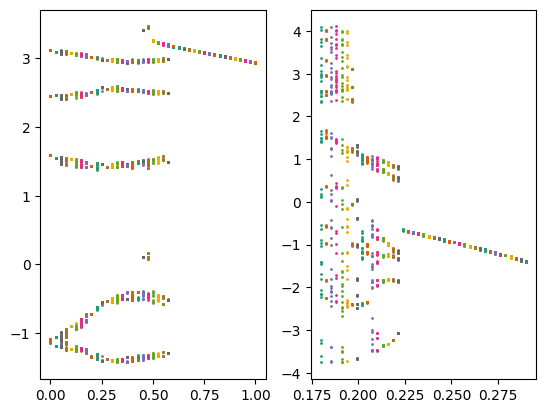

In [77]:
from dynamics_testing import sim

net = copy.deepcopy(net_1)
net.regularization = BEST["spike_c1.0"]
net.compute_weights()

def settle(x, offset=1):
    w = copy.deepcopy(net)
    w.reset_initial_states(offset); w.reset_history()
    for t in range(SETTLE):
        w.advance(x[:, t], save_history=False)
    return w

def maxima(v):
    return v[1:-1][(v[1:-1] > v[:-2]) & (v[1:-1] > v[2:])]

z_ch = settle(TEST["chaotic"][0]).rel_lp.copy()
z_per = settle(TEST["periodic_A"][0]).rel_lp.copy()
A = np.linspace(0, 1, 41)
N_TRANS, N_REC = 300, 500

# start autonomous from the chaotic settle, then sweep the context adiabatically (state carried over)
x = TEST["chaotic"][0]
w0 = settle(x)
w0.frozen = True
for t in range(SETTLE, SETTLE + REENTRAIN):
    w0.advance_nodes(x[:, t], save_history=False)

fig, axes = plt.subplots(1, 2)
for sweep in tqdm((A, A[::-1])):                                              # forward and backward: shows hysteresis
    w = copy.deepcopy(w0)
    for a in sweep:
        w.rel_lp = (1 - a) * z_ch + a * z_per
        xs = []
        for k in range(N_TRANS + N_REC):
            out = w.output_weights @ w.node_states
            if k >= N_TRANS:
                xs.append(out[0])
            w.advance_nodes(out, save_history=False)
        m = maxima(np.asarray(xs))
        axes[0].scatter(np.full(len(m), a), m, s=1)

# ground truth: Thomas over lambda
for b in np.linspace(0.18, 0.29, 41):
    m = maxima(sim(rhs, b, N_REC, (0.1, 0.0, -0.1))[0])
    axes[1].scatter(np.full(len(m), b), m, s=1)
plt.show()

## Theory Section

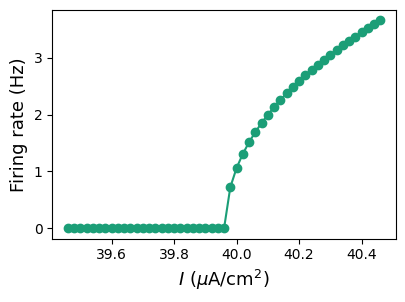

In [95]:
# Firing rate
from lm_neuron_eq import firing_rate

# Is = np.linspace(39.96 - 0.5, 39.96 + 0.5, 51)
# f = np.array([firing_rate(I)[0] for I in tqdm(Is)])**2

# plt.plot(Is, f, 'o-')
# plt.xlabel(r'$I$ ($\mu$A/cm$^2$)')
# plt.ylabel(r'Firing rate squared (Hz$^2$)')
# plt.tight_layout()
# plt.show()

plt.figure(figsize=(6.4 * 0.65, 4.8 * 0.65))
plt.plot(Is, np.sqrt(f), 'o-')
plt.xlabel(r'$I$ ($\mu$A/cm$^2$)')
plt.ylabel(r'Firing rate (Hz)')
plt.tight_layout()

plt.savefig("firing_rate.pdf")
plt.show()

K_eff = 0.1136 rad/ms, R^2 = 0.316, locked = 0.96


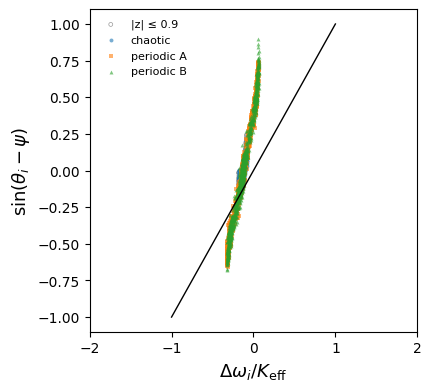

In [86]:
# ===== Locking check (theory piece 4): sin(θ_i − ψ) vs (ω_i − Ω) / K_eff, final model =====
import numpy as np, matplotlib.pyplot as plt
from spike_sharing import SpikingNetwork, I_FLOOR

R_WINDOW, LOCK_THRESH = 200, 0.9
net = SpikingNetwork(model_seed=0)

# Local f–I slope at I_ref (central difference); ω in rad/ms
dI = 1.0
w_ref = 2 * np.pi / net.T_ref
dw_dI = (2 * np.pi / net.reference_period(net.I_ref + dI) - 2 * np.pi / net.reference_period(net.I_ref - dI)) / (2 * dI)

LOCK_DATA = make_states(1, SETTLE, seed=500)
dw_all, sin_all, locked_all, state_all = [], [], [], []
for s in STATES:
    x = LOCK_DATA[s][0]
    net.reset_initial_states(1); net.reset_history()
    I_sum = np.zeros(net.num_links)
    for t in range(SETTLE):
        if t == SETTLE - R_WINDOW:
            t0, c0 = net.link_time, net.spike_counts.copy()
        net.advance(x[:, t], save_history=False)
        if t >= SETTLE - R_WINDOW:
            drive = (net.incidence_T @ ((net.node_states + 1) / 2)) / net.incidence_norm
            I_sum += np.maximum(net.I_ref + net.g_freq * (drive - 0.5), I_FLOOR)
    w_nat = w_ref + dw_dI * (I_sum / R_WINDOW - net.I_ref)          # uncoupled frequency at mean drive
    w_meas = 2 * np.pi * (net.spike_counts - c0) / (net.link_time - t0)
    locked = np.abs(net.rel_lp) > LOCK_THRESH
    dw_all.append(w_nat - w_meas[locked].mean())                     # detuning from locked frequency Ω
    sin_all.append(np.sin(np.angle(net.rel_lp))); locked_all.append(locked); state_all.append(np.full(net.num_links, s))

dw, y, locked, st = map(np.concatenate, (dw_all, sin_all, locked_all, state_all))
a, b = np.polyfit(dw[locked], y[locked], 1)                 # y = a·dw + b
K_eff, delta = 1 / a, -b / a                                # delta: common shift of Ω (even part of H)
r2 = 1 - np.sum((y[locked] - (a * dw[locked] + b)) ** 2) / np.sum((y[locked] - y[locked].mean()) ** 2)
print(f"K_eff = {K_eff:.4g} rad/ms, delta = {delta:.3g} rad/ms, R^2 = {r2:.3f}, locked = {locked.mean():.2f}")

fig, ax = plt.subplots(figsize=(6.4 * 0.65, 4.8 * 0.65))
xs = (dw - delta) / K_eff
ax.scatter(xs[~locked], y[~locked], s=8, facecolors="none", edgecolors="0.6", lw=0.5)

cs = {s: v for s, v in zip(STATES, [colors[4], colors[2], colors[3]])}
for k, c in cs.items():
    ax.scatter(-10, -10, c=c, label=k)
ax.scatter(-10, -10, facecolors="none", edgecolors="0.6", label=f"|z| ≤ {LOCK_THRESH}")
# ms = {s: v for s, v in zip(STATES, ["o", "s", "^"])}

i_s = np.arange(xs.shape[0])
np.random.shuffle(i_s)

cs = [cs[s] for s in st[i_s]]
# ms = [ms[s] for s in st[i_s]]
xs = xs[i_s]

# for i, s in tqdm(enumerate(st)):
#     ax.scatter(xs[i], y[i], s=16, c=cs[s], marker=ms[s], lw=0, alpha=0.25, label=s.replace("_", " "))
ax.scatter(xs, y[i_s], s=16, c=cs, lw=0, alpha=0.25)

ax.plot([-1, 1], [-1, 1], "k-", lw=1)
ax.set(xlim=(-2, 2), ylim=(-1.1, 1.1), xlabel=r"$\Delta\omega_i / K_{\rm eff}$", ylabel=r"$\sin(\theta_i - \psi)$", xticks=[], yticks=[])
ax.legend()

plt.tight_layout()
plt.savefig("locking.pdf")
plt.show()